In [1]:
import ipykernel
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import seaborn as sns
import sklearn

sns.set_theme(style="whitegrid")

In [2]:
data_path = "data/df_yield_merged.csv"
df = pd.read_csv(data_path)

print("Dataset Shape", df.shape)

df.head()

Dataset Shape (25932, 7)


,area,year,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,item,value_hg_ha
0,Albania,1990,1485.0,121.0,16.37,Maize,36613
1,Albania,1990,1485.0,121.0,16.37,Potatoes,66667
2,Albania,1990,1485.0,121.0,16.37,"Rice, paddy",23333
3,Albania,1990,1485.0,121.0,16.37,Sorghum,12500
4,Albania,1990,1485.0,121.0,16.37,Soybeans,7000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25932 entries, 0 to 25931
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   area                           25932 non-null  str    
 1   year                           25932 non-null  int64  
 2   average_rain_fall_mm_per_year  25932 non-null  float64
 3   pesticides_tonnes              25932 non-null  float64
 4   avg_temp                       25932 non-null  float64
 5   item                           25932 non-null  str    
 6   value_hg_ha                    25932 non-null  int64  
dtypes: float64(3), int64(2), str(2)
memory usage: 1.4 MB


In [4]:
df.nunique()

area                               101
year                                23
average_rain_fall_mm_per_year      100
pesticides_tonnes                 1673
avg_temp                          1831
item                                10
value_hg_ha                      11514
dtype: int64

In [5]:
df.describe()
df.describe(include='all')

,area,year,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,item,value_hg_ha
count,25932,25932.000000,25932.000000,25932.000000,25932.000000,25932,25932.000000
unique,101,NaN,NaN,NaN,NaN,10,NaN
top,India,NaN,NaN,NaN,NaN,Potatoes,NaN
freq,3384,NaN,NaN,NaN,NaN,3956,NaN
mean,NaN,2001.556455,1146.836688,34782.573241,20.422251,NaN,76978.132925
std,NaN,7.055924,717.391098,57228.568244,6.439402,NaN,84647.605552
min,NaN,1990.000000,51.000000,0.040000,1.300000,NaN,50.000000
25%,NaN,1995.000000,593.000000,1597.000000,16.580000,NaN,19996.000000
50%,NaN,2001.000000,1083.000000,15373.000000,21.420000,NaN,39530.000000
75%,NaN,2008.000000,1668.000000,45620.000000,26.060000,NaN,104168.000000


In [6]:
df.isnull().sum()

area                             0
year                             0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
item                             0
value_hg_ha                      0
dtype: int64

In [7]:
group_medians = df.groupby(['area', 'item'])['value_hg_ha'].transform('median')

df['yield_shock'] = (df['value_hg_ha'] < group_medians).astype(int)

print("Raw Counts:")
print(df['yield_shock'].value_counts())

print("Percentage Balance:")
print(df['yield_shock'].value_counts(normalize=True))

Raw Counts:
yield_shock
0    13624
1    12308
Name: count, dtype: int64
Percentage Balance:
yield_shock
0    0.525374
1    0.474626
Name: proportion, dtype: float64


/var/folders/r2/l9xjclp174zf83lxsxgmwyjr0000gn/T/ipykernel_40523/1536971298.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Normal harvest (0)', 'Yield Shock (1)'])


Text(0.5, 1.0, 'Target Distribution: Normal Harvest vs. Yield Shock')

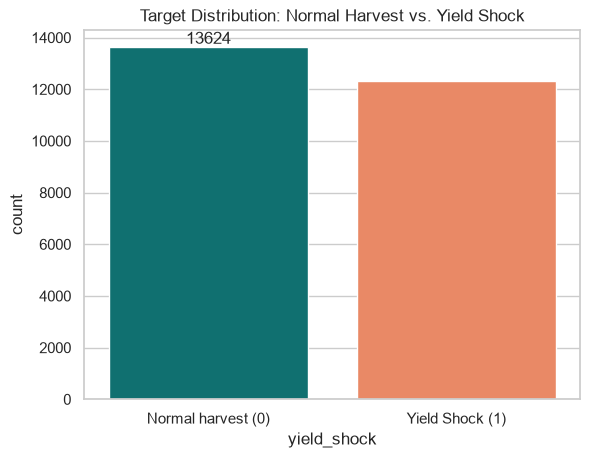

In [8]:
# df['yield_shock'].value_counts().plot(kind='bar', title="Yield Shock Distribution")

ax = sns.countplot(data=df, x="yield_shock", hue = 'yield_shock', palette = ['teal', 'coral'], legend=False)
ax.bar_label(ax.containers[0])
ax.set_xticklabels(['Normal harvest (0)', 'Yield Shock (1)'])
ax.set_title("Target Distribution: Normal Harvest vs. Yield Shock")

In [9]:
y = df['yield_shock']
x = df.drop(columns = ['value_hg_ha', 'yield_shock'])

print("X shape:", x.shape)
print("Y shape:", y.shape)


X shape: (25932, 6)
Y shape: (25932,)


In [10]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,y,
    test_size = 0.2,
    stratify=y,
    random_state = 42
)

print(f"Training Set: {x_train.shape[0]} rows")
print(f"Testing Set: {x_test.shape[0]} rows")

Training Set: 20745 rows
Testing Set: 5187 rows


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_cols = ['year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']
categorical_cols = ['area', 'item']

yield_preprocessor = ColumnTransformer(
    transformers=[
        # (name, transformer, column_list)
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

x_train_transformed = yield_preprocessor.fit_transform(x_train)
print("Original shape: ", x_train.shape)
print("New shape: ", x_train_transformed.shape)

feature_names = yield_preprocessor.get_feature_names_out()
print("\nFirst 10 column names:")
print(feature_names[:10])


Original shape:  (20745, 6)
New shape:  (20745, 115)

First 10 column names:
['num__year' 'num__average_rain_fall_mm_per_year' 'num__pesticides_tonnes'
 'num__avg_temp' 'cat__area_Albania' 'cat__area_Algeria'
 'cat__area_Angola' 'cat__area_Argentina' 'cat__area_Armenia'
 'cat__area_Australia']


In [12]:
from sklearn.linear_model import LogisticRegression
import numpy as np

yield_model = LogisticRegression(l1_ratio=1, solver='liblinear', C=1.0, random_state=42, max_iter=1000)

yield_model.fit(x_train_transformed, y_train)

coefficients = yield_model.coef_[0]

mask = (coefficients != 0)
print(f"Total features: {len(coefficients)}")
print(f"Features kept: {np.sum(mask)}")
print(f"Features zeroed: {np.sum(~mask)}")

print("Kept features: ", feature_names[mask][:5])
print("UnKept features: ", feature_names[~mask][:5])

Total features: 115
Features kept: 89
Features zeroed: 26
Kept features:  ['num__year' 'num__average_rain_fall_mm_per_year' 'num__pesticides_tonnes'
 'num__avg_temp' 'cat__area_Albania']
UnKept features:  ['cat__area_Armenia' 'cat__area_Austria' 'cat__area_Belarus'
 'cat__area_Botswana' 'cat__area_Burkina Faso']


In [13]:
x_train_selected = x_train_transformed[:, mask]

x_test_processed = yield_preprocessor.transform(x_test)
x_test_selected = x_test_processed[:, mask]

print("Selected Train Shape: ", x_train_selected.shape)
print("Selected Test Shape: ", x_test_selected.shape)

final_yield_model = LogisticRegression(random_state=42, max_iter=1000)
final_yield_model.fit(x_train_selected, y_train)

Selected Train Shape:  (20745, 89)
Selected Test Shape:  (5187, 89)


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

Accuracy:  0.7355 (73.55%)
Precision: 0.7185 (71.85%)
Recall:    0.7279 (72.79%)


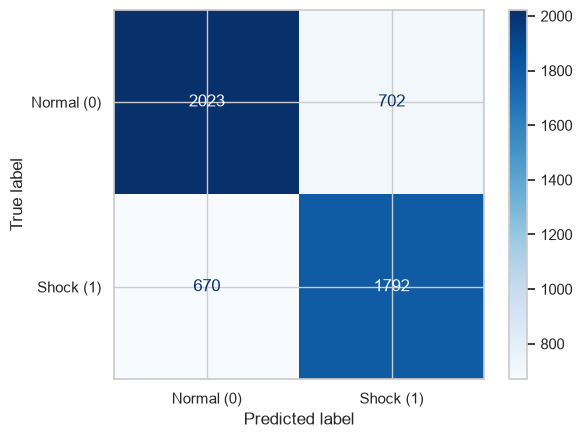

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

y_prediction = final_yield_model.predict(x_test_selected)

acc = accuracy_score(y_test, y_prediction)
prec = precision_score(y_test, y_prediction)
rec = recall_score(y_test, y_prediction)

print(f"Accuracy:  {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision: {prec:.4f} ({prec*100:.2f}%)")
print(f"Recall:    {rec:.4f} ({rec*100:.2f}%)")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_prediction,
    display_labels=['Normal (0)', 'Shock (1)'],
    cmap = 'Blues'
)

In [15]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(final_yield_model, "models/final_model.joblib")
joblib.dump(yield_preprocessor, "models/preprocessor.joblib")

print("Artfacts successfulyy saved to disk!")

Artfacts successfulyy saved to disk!
